In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
import glob
import os
from scipy.spatial import cKDTree
from itertools import zip_longest
import matplotlib.ticker as ticker

In [ ]:
import glob
import matplotlib.font_manager as fm

# Load all CMU fonts
for p in glob.glob("/home1/binhaoli/.local/share/fonts/cmun*.ttf"):
    fm.fontManager.addfont(p)

plt.rcParams["font.family"] = "CMU Sans Serif"
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["axes.unicode_minus"] = False

In [ ]:
import 

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
import glob
import os
from scipy.spatial import cKDTree
from itertools import zip_longest
from cmcrameri import cm

def resample_by_arclength(P, ds=1.0):
    """P: Nx2 polyline. Returns roughly uniform-arc-length resampling."""
    seg = np.linalg.norm(np.diff(P, axis=0), axis=1)
    s = np.concatenate(([0.0], np.cumsum(seg)))
    L = s[-1]
    if L == 0:  # degenerate
        return P[[0]].copy()
    s_new = np.arange(0, L + 1e-9, ds)
    # linear interp on cumulative arclength
    Px = np.interp(s_new, s, P[:,0])
    Py = np.interp(s_new, s, P[:,1])
    return np.column_stack([Px, Py])

def directed_nn_distances(A, B):
    """For each point in A, distance to nearest point in B."""
    tree = cKDTree(B)
    d, _ = tree.query(A, k=1, workers=-1)
    return d

def distance_distribution(A, B, ds=1.0):
    """Compute symmetric distribution + standard metrics."""
    Au = resample_by_arclength(A, ds=ds)
    Bu = resample_by_arclength(B, ds=ds)

    dAB = directed_nn_distances(Au, Bu)
    dBA = directed_nn_distances(Bu, Au)
    D = np.concatenate([dAB, dBA])
    
    return D, dAB, dBA

def compute_pdf(D, bins):
    """Return normalized PDF for one realization."""
    pdf, edges = np.histogram(D, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    return centers, pdf

def average_histograms(list_of_D, bins):
    """Average PDFs from multiple realizations."""
    all_pdfs = []
    for D in list_of_D:
        # print("len(D):", len(D))
        # print("NaN count:", np.isnan(D).sum())
        # print("min, max:", np.nanmin(D), np.nanmax(D))
        _, pdf = compute_pdf(D, bins)
        all_pdfs.append(pdf)

    all_pdfs = np.vstack(all_pdfs)  # shape (N_MC, N_bins)
    pdf_mean = np.mean(all_pdfs, axis=0)
    pdf_std  = np.std(all_pdfs, axis=0)  # uncertainty band

    centers = 0.5 * (bins[:-1] + bins[1:])
    return centers, pdf_mean, pdf_std

In [7]:
import pickle

with open("result.pkl", "rb") as f:
    result = pickle.load(f)

In [8]:
hsdf_dist_fp = {
    'fp_fmm': [],
    'fp_dijkstra': [],
    'lrp': []
}
for i in range(100):
    hist_dist, _, _ = distance_distribution(result['fp_rk45'][i], result['fp_fmm'][i], ds=1.0)
    hsdf_dist_fp['fp_fmm'].append(max(hist_dist))

    hist_dist, _, _ = distance_distribution(result['fp_rk45'][i], result['fp_dijkstra'][i], ds=1.0)
    hsdf_dist_fp['fp_dijkstra'].append(max(hist_dist))

    hist_dist, _, _ = distance_distribution(result['fp_rk45'][i], result['lrp'][i], ds=1.0)
    hsdf_dist_fp['lrp'].append(max(hist_dist))

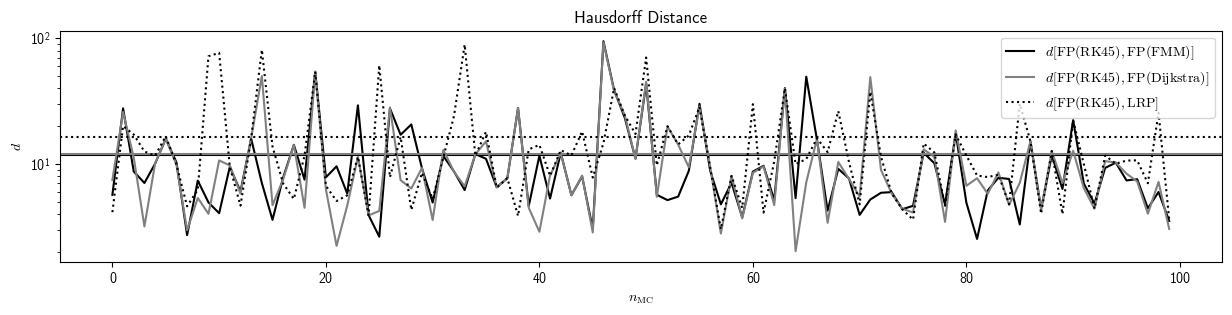

In [49]:
fig, ax = plt.subplots(figsize=(15,3))
ax.plot(hsdf_dist_fp['fp_fmm'], color='k', label='$d[\\text{FP(RK45)}, \\text{FP(FMM)}]$')
ax.axhline(np.mean(hsdf_dist_fp['fp_fmm']), color='k')

ax.plot(hsdf_dist_fp['fp_dijkstra'], color='gray', label='$d[\\text{FP(RK45)}, \\text{FP(Dijkstra)}]$')
ax.axhline(np.mean(hsdf_dist_fp['fp_dijkstra']), color='gray')

ax.plot(hsdf_dist_fp['lrp'], color='k', ls=':', label='$d[\\text{FP(RK45)}, \\text{LRP}]$')
ax.axhline(np.mean(hsdf_dist_fp['lrp']), color='k', ls=':')

# ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$n_{\\text{MC}}$")
ax.set_ylabel("$d$")
ax.set_title("Hausdorff Distance")
# ax.grid(True, which='both', color='gray', linestyle='-', linewidth=0.8, alpha=0.6)
ax.legend()


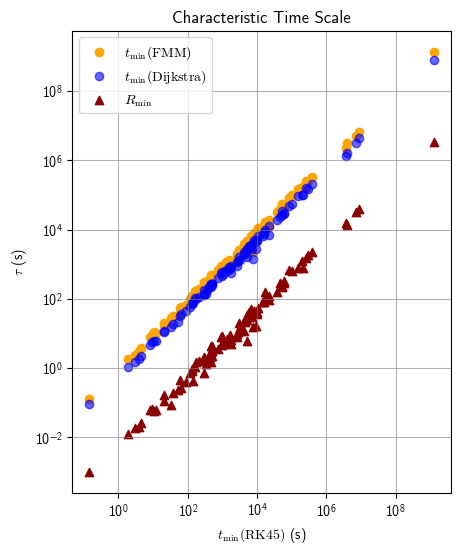

In [53]:
fig, ax = plt.subplots(figsize=(10,6))
ax.scatter(result['tMin_rk45'], result['tMin_fmm'], color='orange', label='$t_{\\text{min}}\\text{(FMM)}$', alpha=1)
ax.scatter(result['tMin_rk45'], result['tMin_dijkstra'], color='blue', label='$t_{\\text{min}}\\text{(Dijkstra)}$', alpha=0.6)
ax.scatter(result['tMin_rk45'], result['rMin'], color='darkred', marker='^', label='$R_{\\text{min}}$', alpha=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$t_{\\text{min}}\\text{(RK45)}$ (s)")
ax.set_ylabel("$\\tau$ (s)")
ax.grid(True, which='both', color='gray', linestyle='-', linewidth=0.8, alpha=0.6)
ax.set_aspect('equal', adjustable='box')
ax.set_title("Characteristic Time Scale")
ax.legend()

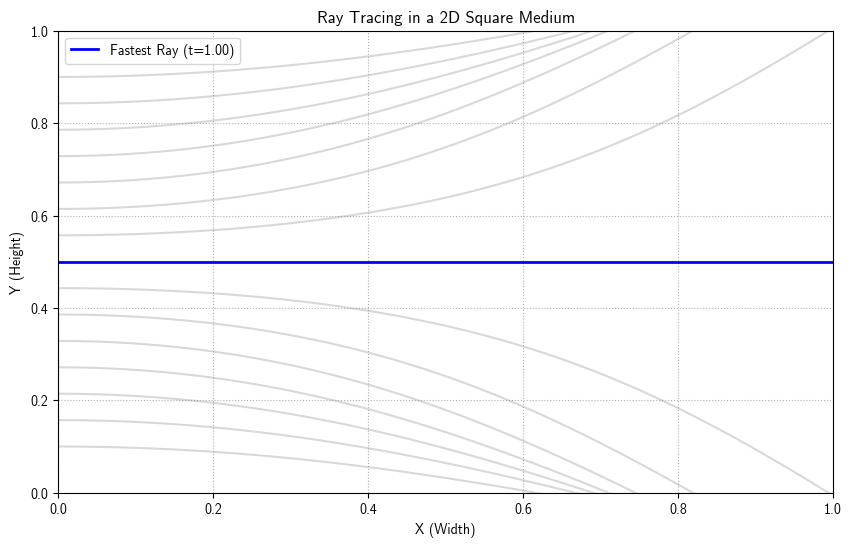

The fastest ray started at y = 0.50


In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Define the Medium (Refractive Index U and its gradients)
# We'll create a "gradient" where it's faster (lower U) in the middle.
def get_U(x, y):
    # Example: A medium that is 'faster' in the center (y=0.5)
    return 1.5 - 0.5 * np.exp(-((y - 0.5)**2) / 0.1)

def get_grad_U(x, y):
    # Partial derivatives of the U function above
    U = get_U(x, y)
    dUdx = 0 # No change in x for this example
    dUdy = -0.5 * np.exp(-((y - 0.5)**2) / 0.1) * (-2 * (y - 0.5) / 0.1)
    return dUdx, dUdy

# 2. Define the Differential Equations (from your image)
def ray_equations(s, state):
    x, y, phi, time = state
    U = get_U(x, y)
    dUdx, dUdy = get_grad_U(x, y)
    
    dxds = np.cos(phi)
    dyds = np.sin(phi)
    dphids = (1/U) * (np.cos(phi) * dUdy - np.sin(phi) * dUdx)
    dtods = U  # Optical path length (proportional to time)
    
    return [dxds, dyds, dphids, dtods]

# 3. Setup the Simulation
num_rays = 15
y_starts = np.linspace(0.1, 0.9, num_rays)
results = []

# Termination condition: stop when ray hits the right boundary (x=1)
def hit_right_wall(s, state): return state[0] - 1.0
hit_right_wall.terminal = True

# 4. Run the Tracing
plt.figure(figsize=(10, 6))
fastest_time = float('inf')
best_ray_idx = -1

for i, y0 in enumerate(y_starts):
    initial_state = [0.0, y0, 0.0, 0.0] # x, y, phi (pointing right), time
    sol = solve_ivp(ray_equations, [0, 2], initial_state, 
                     events=hit_right_wall, max_step=0.01)
    
    x_vals, y_vals = sol.y[0], sol.y[1]
    total_time = sol.y[3][-1]
    results.append(total_time)
    
    # Check if this ray reached the end and is the fastest
    if x_vals[-1] >= 0.99:
        if total_time < fastest_time:
            fastest_time = total_time
            best_ray_idx = i
        plt.plot(x_vals, y_vals, color='gray', alpha=0.3)
    else:
        plt.plot(x_vals, y_vals, color='red', linestyle='--', alpha=0.2) # Ray lost

# Highlight the fastest ray
best_sol = solve_ivp(ray_equations, [0, 2], [0.0, y_starts[best_ray_idx], 0.0, 0.0], events=hit_right_wall)
plt.plot(best_sol.y[0], best_sol.y[1], color='blue', linewidth=2, label=f'Fastest Ray (t={fastest_time:.2f})')

# Formatting
plt.title("Ray Tracing in a 2D Square Medium")
plt.xlabel("X (Width)")
plt.ylabel("Y (Height)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(True, linestyle=':')
plt.show()

print(f"The fastest ray started at y = {y_starts[best_ray_idx]:.2f}")